# Experiment 4 - Variational Autoencoder (VAE): Image Generation and Reconstruction


In [ ]:
import tensorflow as tf, numpy as np, matplotlib.pyplot as plt, pandas as pd
from tensorflow.keras import layers, Model
from tensorflow.keras.datasets import mnist
print("TensorFlow:", tf.__version__)
tf.random.set_seed(42); np.random.seed(42)

TensorFlow: 2.21.0


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Train: (60000, 784) Test: (10000, 784)


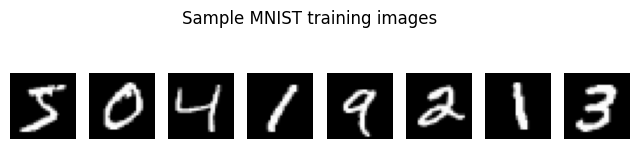

In [ ]:
(x_train, _), (x_test, y_test) = mnist.load_data()
x_train = (x_train.astype("float32") / 255.0).reshape(-1, 784)
x_test = (x_test.astype("float32") / 255.0).reshape(-1, 784)
print("Train:", x_train.shape, "Test:", x_test.shape)
plt.figure(figsize=(8,2))
for i in range(8):
    plt.subplot(1,8,i+1); plt.imshow(x_train[i].reshape(28,28), cmap="gray"); plt.axis("off")
plt.suptitle("Sample MNIST training images"); plt.show()

In [ ]:
latent_dim = 2

class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        eps = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * eps

encoder_inputs = layers.Input(shape=(784,))
x = layers.Dense(256, activation="relu")(encoder_inputs)
z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])
encoder = Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")

latent_inputs = layers.Input(shape=(latent_dim,))
x = layers.Dense(256, activation="relu")(latent_inputs)
decoder_outputs = layers.Dense(784, activation="sigmoid")(x)
decoder = Model(latent_inputs, decoder_outputs, name="decoder")

class VAE(Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs); self.encoder=encoder; self.decoder=decoder
        self.total_tracker=tf.keras.metrics.Mean(name="loss")
        self.recon_tracker=tf.keras.metrics.Mean(name="reconstruction_loss")
        self.kl_tracker=tf.keras.metrics.Mean(name="kl_loss")
    @property
    def metrics(self): return [self.total_tracker,self.recon_tracker,self.kl_tracker]
    def train_step(self, data):
        if isinstance(data, tuple): data=data[0]
        with tf.GradientTape() as tape:
            zm,zlv,z=self.encoder(data, training=True)
            reconstruction=self.decoder(z, training=True)
            # binary_crossentropy returns average over features, so we multiply by 784 to get the sum
            bce=tf.keras.losses.binary_crossentropy(data,reconstruction)
            recon=tf.reduce_mean(bce * 784)
            kl=tf.reduce_mean(-0.5*tf.reduce_sum(1+zlv-tf.square(zm)-tf.exp(zlv),axis=1))
            total=recon+kl
        grads=tape.gradient(total,self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads,self.trainable_weights))
        self.total_tracker.update_state(total); self.recon_tracker.update_state(recon); self.kl_tracker.update_state(kl)
        return {m.name:m.result() for m in self.metrics}
    def test_step(self, data):
        if isinstance(data, tuple): data=data[0]
        zm,zlv,z=self.encoder(data, training=False); reconstruction=self.decoder(z, training=False)
        bce=tf.keras.losses.binary_crossentropy(data,reconstruction)
        recon=tf.reduce_mean(bce * 784)
        kl=tf.reduce_mean(-0.5*tf.reduce_sum(1+zlv-tf.square(zm)-tf.exp(zlv),axis=1))
        self.total_tracker.update_state(recon+kl); self.recon_tracker.update_state(recon); self.kl_tracker.update_state(kl)
        return {m.name:m.result() for m in self.metrics}

vae=VAE(encoder,decoder)
vae.compile(optimizer=tf.keras.optimizers.Adam())
encoder.summary(); decoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 784)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 256)       │    200,960 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │        514 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │        514 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling_1          │ (None, 2)         │          0 │ z_mean[0][0],     │
│ (Sampling)          │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 201,988 (789.02 KB)

 Trainable params: 201,988 (789.02 KB)

 Non-trainable params: 0 (0.00 B)

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 202,256 (790.06 KB)

 Trainable params: 202,256 (790.06 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

EPOCHS = 10
history = vae.fit(x_train, epochs=EPOCHS, batch_size=128, verbose=1)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - kl_loss: 9.1081 - loss: 209.4694 - reconstruction_loss: 200.3613 
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - kl_loss: 4.9831 - loss: 176.0490 - reconstruction_loss: 171.0658
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - kl_loss: 4.6960 - loss: 170.8564 - reconstruction_loss: 166.1604
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - kl_loss: 4.8051 - loss: 167.7720 - reconstruction_loss: 162.9670
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - kl_loss: 4.9311 - loss: 165.6590 - reconstruction_loss: 160.7279
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - kl_loss: 5.0680 - loss: 163.9502 - reconstruction_loss: 158.8820
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - kl_loss: 5.2127 - loss: 162.2513 - reconstruction_loss: 157.0386
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - kl_loss: 5.3702 - loss: 160.7439 - reconstruction_loss: 155.3737
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9m

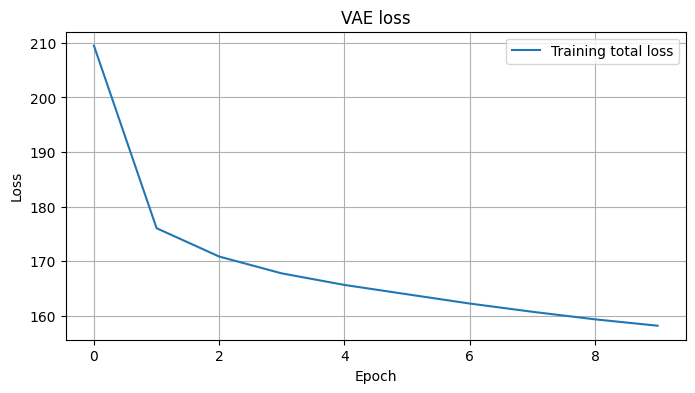

In [ ]:
plt.figure(figsize=(8,4))
plt.plot(history.history["loss"], label="Training total loss")
if "val_loss" in history.history: plt.plot(history.history["val_loss"], label="Validation total loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("VAE loss"); plt.legend(); plt.grid(True); plt.show()

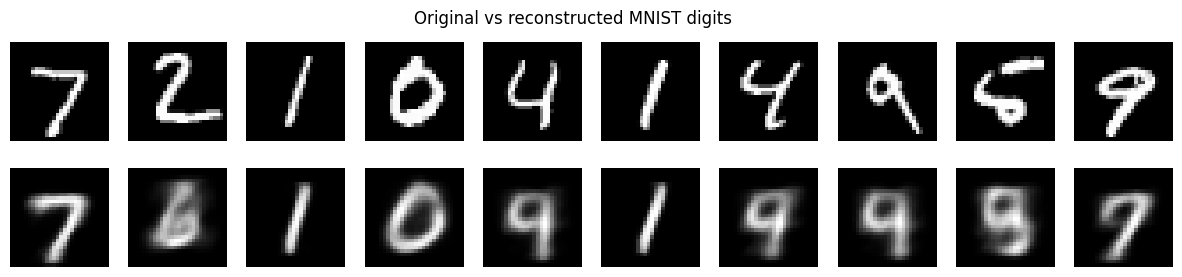

In [ ]:
n=10
original=x_test[:n]
zm,zlv,z=encoder.predict(original,verbose=0)
reconstructed=decoder.predict(z,verbose=0)
fig, axes=plt.subplots(2,n,figsize=(15,3))
for i in range(n):
    axes[0,i].imshow(original[i].reshape(28,28),cmap="gray"); axes[0,i].axis("off")
    axes[1,i].imshow(reconstructed[i].reshape(28,28),cmap="gray"); axes[1,i].axis("off")
axes[0,0].set_ylabel("Original"); axes[1,0].set_ylabel("Reconstructed")
plt.suptitle("Original vs reconstructed MNIST digits"); plt.show()

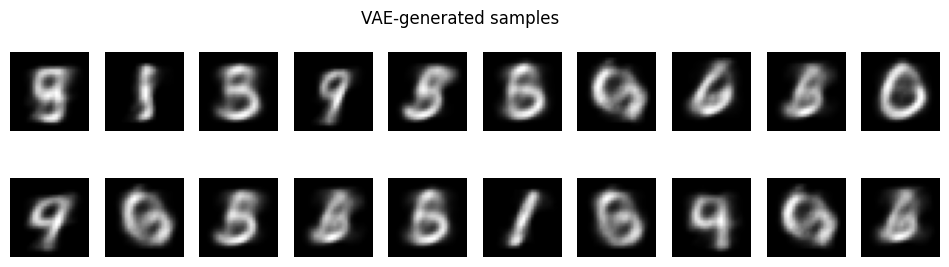

In [ ]:
# Generate images by sampling random vectors from the 2-D standard normal latent space.
z_samples=np.random.normal(size=(20,latent_dim)).astype("float32")
generated=decoder.predict(z_samples,verbose=0)
fig,axes=plt.subplots(2,10,figsize=(12,3))
for ax,img in zip(axes.flat,generated):
    ax.imshow(img.reshape(28,28),cmap="gray"); ax.axis("off")
plt.suptitle("VAE-generated samples"); plt.show()

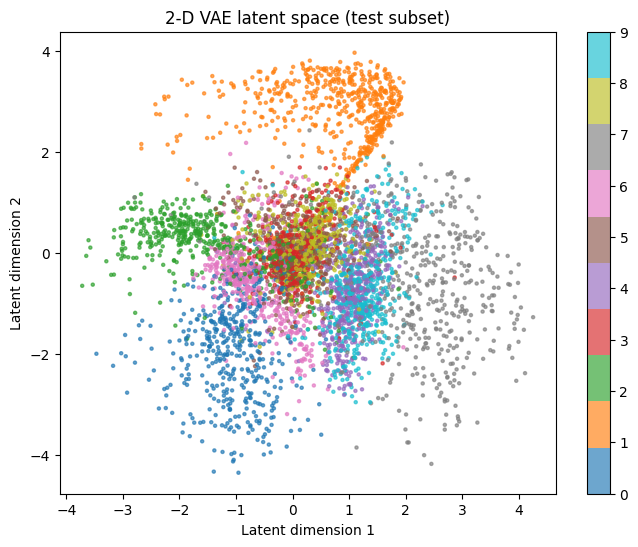

In [ ]:
# Encode test examples and visualize the latent space; color points by their MNIST labels.
z_mean_test,_,_=encoder.predict(x_test[:5000],verbose=0)
plt.figure(figsize=(8,6))
sc=plt.scatter(z_mean_test[:,0],z_mean_test[:,1],c=y_test[:5000],s=5,cmap="tab10",alpha=.65)
plt.colorbar(sc,ticks=range(10)); plt.xlabel("Latent dimension 1"); plt.ylabel("Latent dimension 2")
plt.title("2-D VAE latent space (test subset)"); plt.show()